In [1]:
!pip install pandas matplotlib sqlalchemy pymysql

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
from sqlalchemy import create_engine , URL
from getpass import getpass

In [3]:
username = "root"
password = getpass("Enter your MySQL Password: ")
host = "localhost"
database = "sales_analysis"

url = URL.create(
    drivername="mysql+pymysql",
    username=username,
    password=password,
    host=host,
    database=database
)

engine = create_engine(url)

print("Database Connection created Successfully")

Enter your MySQL Password:  ········


Database Connection created Successfully


In [4]:
# To Test a Connection

In [5]:
with engine.connect() as connection:
    print("Connected to MySQL successfully")

Connected to MySQL successfully


In [6]:
# To Bring that specifc Data

In [9]:
query = """
    SELECT *
    FROM sales_table
    ORDER BY sale_date
"""

df = pd.read_sql(query,engine)

df.head(10)

,sale_id,sale_date,amount
0,1,2026-01-01,1000.0
1,2,2026-01-01,1500.0
2,3,2026-01-02,2000.0
3,4,2026-01-02,1000.0
4,5,2026-01-03,2500.0
5,6,2026-01-03,1500.0
6,7,2026-01-04,3000.0
7,8,2026-01-04,2000.0
8,9,2026-01-05,3500.0
9,10,2026-01-05,2500.0


In [11]:
# For Shape

df.shape

(60, 3)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   sale_id    60 non-null     int64  
 1   sale_date  60 non-null     object 
 2   amount     60 non-null     float64
dtypes: float64(1), int64(1), object(1)
memory usage: 1.5+ KB


In [13]:
df.describe()

,sale_id,amount
count,60.000000,60.000000
mean,30.500000,6366.666667
std,17.464249,3648.620202
min,1.000000,1000.000000
25%,15.750000,3500.000000
50%,30.500000,5750.000000
75%,45.250000,8625.000000
max,60.000000,16000.000000


In [14]:
# Convert sale_date into datetime

In [15]:
df["date_time"] = pd.to_datetime(df["sale_date"])

print(df.dtypes)

sale_id              int64
sale_date           object
amount             float64
date_time    datetime64[s]
dtype: object


In [17]:
# Why do we do this?

# Because dates should be stored as datetime objects when performing date-based 
# operations in Python.

In [20]:
# df["year"] = df["sale_date"].dt.year
# df["month"] = df["sale_date"].dt.month
# df["day"] = df["sale_date"].dt.day

# df.head()

In [ ]:
# Calculate daily average sales using Pandas

In [21]:
daily_sales = df.groupby("sale_date")["amount"].mean()

print(daily_sales)

sale_date
2026-01-01     1250.0
2026-01-02     1500.0
2026-01-03     2000.0
2026-01-04     2500.0
2026-01-05     3000.0
2026-01-06     2500.0
2026-01-07     3250.0
2026-01-08     3750.0
2026-01-09     4250.0
2026-01-10     4750.0
2026-01-11     3750.0
2026-01-12     5000.0
2026-01-13     5500.0
2026-01-14     6000.0
2026-01-15     6500.0
2026-01-16     5000.0
2026-01-17     6500.0
2026-01-18     7000.0
2026-01-19     7500.0
2026-01-20     8000.0
2026-01-21     6000.0
2026-01-22     8500.0
2026-01-23     9250.0
2026-01-24    10000.0
2026-01-25     8500.0
2026-01-26    10500.0
2026-01-27    11000.0
2026-01-28    11750.0
2026-01-29    12500.0
2026-01-30    13500.0
Name: amount, dtype: float64


In [22]:
daily_sales = df.groupby("sale_date")["amount"].sum()

print(daily_sales)

sale_date
2026-01-01     2500.0
2026-01-02     3000.0
2026-01-03     4000.0
2026-01-04     5000.0
2026-01-05     6000.0
2026-01-06     5000.0
2026-01-07     6500.0
2026-01-08     7500.0
2026-01-09     8500.0
2026-01-10     9500.0
2026-01-11     7500.0
2026-01-12    10000.0
2026-01-13    11000.0
2026-01-14    12000.0
2026-01-15    13000.0
2026-01-16    10000.0
2026-01-17    13000.0
2026-01-18    14000.0
2026-01-19    15000.0
2026-01-20    16000.0
2026-01-21    12000.0
2026-01-22    17000.0
2026-01-23    18500.0
2026-01-24    20000.0
2026-01-25    17000.0
2026-01-26    21000.0
2026-01-27    22000.0
2026-01-28    23500.0
2026-01-29    25000.0
2026-01-30    27000.0
Name: amount, dtype: float64


In [23]:
daily_summary = df.groupby("sale_date").agg(
    total_transactions=("amount","count"),
    daily_total_sales=("amount","sum"),
    daily_average_sales=("amount","mean")
).reset_index()

daily_summary.head(10)

,sale_date,total_transactions,daily_total_sales,daily_average_sales
0,2026-01-01,2,2500.0,1250.0
1,2026-01-02,2,3000.0,1500.0
2,2026-01-03,2,4000.0,2000.0
3,2026-01-04,2,5000.0,2500.0
4,2026-01-05,2,6000.0,3000.0
5,2026-01-06,2,5000.0,2500.0
6,2026-01-07,2,6500.0,3250.0
7,2026-01-08,2,7500.0,3750.0
8,2026-01-09,2,8500.0,4250.0
9,2026-01-10,2,9500.0,4750.0


In [24]:
# Calculate previous day's sales using shift()

In [25]:
daily_summary["previous_day_sales"] = (
    daily_summary["daily_total_sales"].shift(1)
)

daily_summary.head()

,sale_date,total_transactions,daily_total_sales,daily_average_sales,previous_day_sales
0,2026-01-01,2,2500.0,1250.0,NaN
1,2026-01-02,2,3000.0,1500.0,2500.0
2,2026-01-03,2,4000.0,2000.0,3000.0
3,2026-01-04,2,5000.0,2500.0,4000.0
4,2026-01-05,2,6000.0,3000.0,5000.0


In [26]:
# Calculate sales difference
# calculate the difference between current and previous day's sales.

In [27]:
daily_summary["sales_difference"] = (
    daily_summary["daily_total_sales"] - daily_summary["previous_day_sales"]
)

daily_summary.head(10)

,sale_date,total_transactions,daily_total_sales,daily_average_sales,previous_day_sales,sales_difference
0,2026-01-01,2,2500.0,1250.0,NaN,NaN
1,2026-01-02,2,3000.0,1500.0,2500.0,500.0
2,2026-01-03,2,4000.0,2000.0,3000.0,1000.0
3,2026-01-04,2,5000.0,2500.0,4000.0,1000.0
4,2026-01-05,2,6000.0,3000.0,5000.0,1000.0
5,2026-01-06,2,5000.0,2500.0,6000.0,-1000.0
6,2026-01-07,2,6500.0,3250.0,5000.0,1500.0
7,2026-01-08,2,7500.0,3750.0,6500.0,1000.0
8,2026-01-09,2,8500.0,4250.0,7500.0,1000.0
9,2026-01-10,2,9500.0,4750.0,8500.0,1000.0


In [28]:
# Calculate growth percentage
# calculate the day-over-day percentage growth.


In [30]:
daily_summary["growth_percentage"] = (
    (
        daily_summary["daily_total_sales"] - daily_summary["previous_day_sales"]
    ) / daily_summary["previous_day_sales"].replace(0,float("nan"))
) * 100

daily_summary["growth_percentage"] = (
    daily_summary["growth_percentage"].round(2)
)

daily_summary.head(10)

,sale_date,total_transactions,daily_total_sales,daily_average_sales,previous_day_sales,sales_difference,growth_percentage
0,2026-01-01,2,2500.0,1250.0,NaN,NaN,NaN
1,2026-01-02,2,3000.0,1500.0,2500.0,500.0,20.00
2,2026-01-03,2,4000.0,2000.0,3000.0,1000.0,33.33
3,2026-01-04,2,5000.0,2500.0,4000.0,1000.0,25.00
4,2026-01-05,2,6000.0,3000.0,5000.0,1000.0,20.00
5,2026-01-06,2,5000.0,2500.0,6000.0,-1000.0,-16.67
6,2026-01-07,2,6500.0,3250.0,5000.0,1500.0,30.00
7,2026-01-08,2,7500.0,3750.0,6500.0,1000.0,15.38
8,2026-01-09,2,8500.0,4250.0,7500.0,1000.0,13.33
9,2026-01-10,2,9500.0,4750.0,8500.0,1000.0,11.76


In [31]:
# Calculate next day's sales using shift(-1)

In [33]:
daily_summary["next_day_sales"] = (
    daily_summary["daily_total_sales"].shift(-1)
)

daily_summary

,sale_date,total_transactions,daily_total_sales,daily_average_sales,previous_day_sales,sales_difference,growth_percentage,next_day_sales
0,2026-01-01,2,2500.0,1250.0,NaN,NaN,NaN,3000.0
1,2026-01-02,2,3000.0,1500.0,2500.0,500.0,20.00,4000.0
2,2026-01-03,2,4000.0,2000.0,3000.0,1000.0,33.33,5000.0
3,2026-01-04,2,5000.0,2500.0,4000.0,1000.0,25.00,6000.0
4,2026-01-05,2,6000.0,3000.0,5000.0,1000.0,20.00,5000.0
5,2026-01-06,2,5000.0,2500.0,6000.0,-1000.0,-16.67,6500.0
6,2026-01-07,2,6500.0,3250.0,5000.0,1500.0,30.00,7500.0
7,2026-01-08,2,7500.0,3750.0,6500.0,1000.0,15.38,8500.0
8,2026-01-09,2,8500.0,4250.0,7500.0,1000.0,13.33,9500.0
9,2026-01-10,2,9500.0,4750.0,8500.0,1000.0,11.76,7500.0


In [34]:
# Calculate 3-day moving average

# calculate a moving average using Pandas.

In [36]:
daily_summary["moving_average_3_days"] = (
    daily_summary["daily_total_sales"]
    .rolling(window=3)
    .mean()
)

daily_summary.head(10)

,sale_date,total_transactions,daily_total_sales,daily_average_sales,previous_day_sales,sales_difference,growth_percentage,next_day_sales,moving_average_3_days
0,2026-01-01,2,2500.0,1250.0,NaN,NaN,NaN,3000.0,NaN
1,2026-01-02,2,3000.0,1500.0,2500.0,500.0,20.00,4000.0,NaN
2,2026-01-03,2,4000.0,2000.0,3000.0,1000.0,33.33,5000.0,3166.666667
3,2026-01-04,2,5000.0,2500.0,4000.0,1000.0,25.00,6000.0,4000.000000
4,2026-01-05,2,6000.0,3000.0,5000.0,1000.0,20.00,5000.0,5000.000000
5,2026-01-06,2,5000.0,2500.0,6000.0,-1000.0,-16.67,6500.0,5333.333333
6,2026-01-07,2,6500.0,3250.0,5000.0,1500.0,30.00,7500.0,5833.333333
7,2026-01-08,2,7500.0,3750.0,6500.0,1000.0,15.38,8500.0,6333.333333
8,2026-01-09,2,8500.0,4250.0,7500.0,1000.0,13.33,9500.0,7500.000000
9,2026-01-10,2,9500.0,4750.0,8500.0,1000.0,11.76,7500.0,8500.000000


In [37]:
# Calculate 7-day moving average

In [38]:
daily_summary["moving_average_7_days"] = (
    daily_summary["daily_total_sales"]
    .rolling(window=7)
    .mean()
)

daily_summary.head(15)

,sale_date,total_transactions,daily_total_sales,daily_average_sales,previous_day_sales,sales_difference,growth_percentage,next_day_sales,moving_average_3_days,moving_average_7_days
0,2026-01-01,2,2500.0,1250.0,NaN,NaN,NaN,3000.0,NaN,NaN
1,2026-01-02,2,3000.0,1500.0,2500.0,500.0,20.00,4000.0,NaN,NaN
2,2026-01-03,2,4000.0,2000.0,3000.0,1000.0,33.33,5000.0,3166.666667,NaN
3,2026-01-04,2,5000.0,2500.0,4000.0,1000.0,25.00,6000.0,4000.000000,NaN
4,2026-01-05,2,6000.0,3000.0,5000.0,1000.0,20.00,5000.0,5000.000000,NaN
5,2026-01-06,2,5000.0,2500.0,6000.0,-1000.0,-16.67,6500.0,5333.333333,NaN
6,2026-01-07,2,6500.0,3250.0,5000.0,1500.0,30.00,7500.0,5833.333333,4571.428571
7,2026-01-08,2,7500.0,3750.0,6500.0,1000.0,15.38,8500.0,6333.333333,5285.714286
8,2026-01-09,2,8500.0,4250.0,7500.0,1000.0,13.33,9500.0,7500.000000,6071.428571
9,2026-01-10,2,9500.0,4750.0,8500.0,1000.0,11.76,7500.0,8500.000000,6857.142857


In [39]:
# Visualize daily sales using Matplotlib

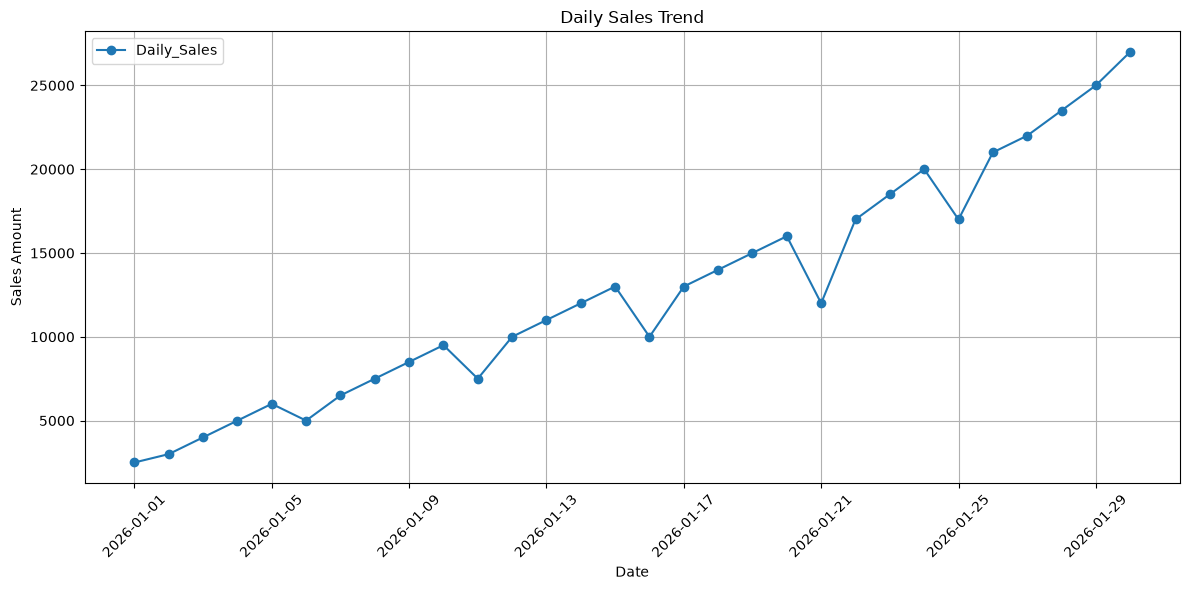

In [40]:
plt.figure(figsize=(12,6))

plt.plot(
    daily_summary["sale_date"],
    daily_summary["daily_total_sales"],
    marker="o",
    label="Daily_Sales"
)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales Amount")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [41]:
# Visualize moving averages

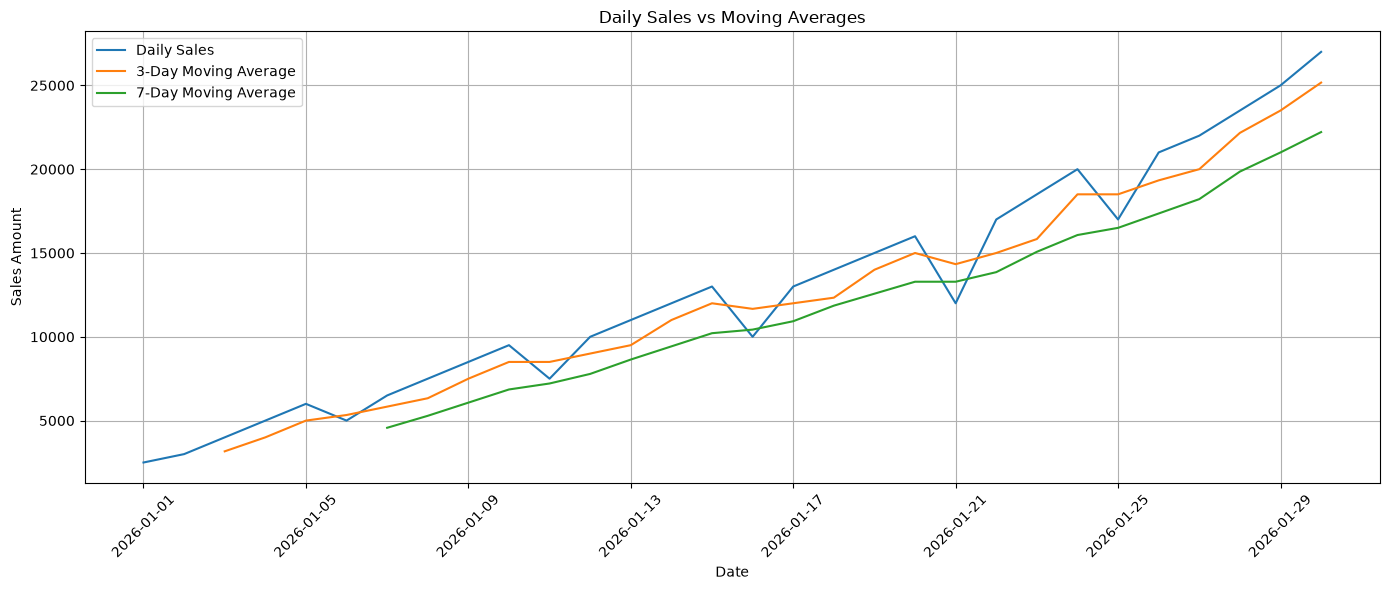

In [42]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_summary["sale_date"],
    daily_summary["daily_total_sales"],
    label="Daily Sales"
)

plt.plot(
    daily_summary["sale_date"],
    daily_summary["moving_average_3_days"],
    label="3-Day Moving Average"
)

plt.plot(
    daily_summary["sale_date"],
    daily_summary["moving_average_7_days"],
    label="7-Day Moving Average"
)

plt.title("Daily Sales vs Moving Averages")

plt.xlabel("Date")

plt.ylabel("Sales Amount")

plt.xticks(rotation=45)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

In [43]:
# Visualize daily growth percentage

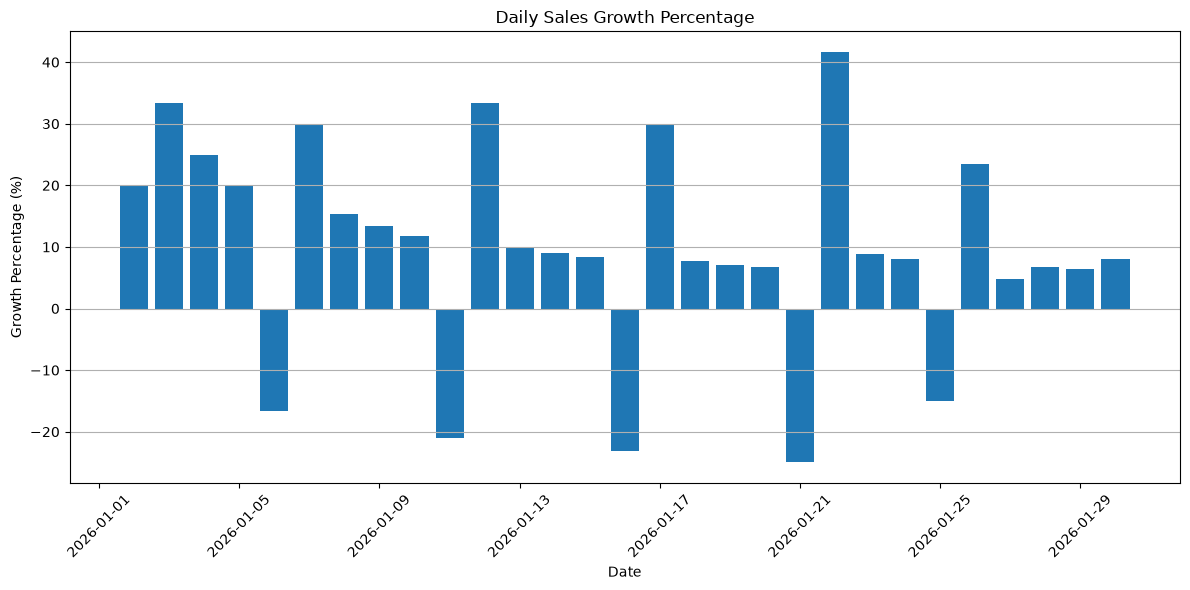

In [44]:
plt.figure(figsize=(12, 6))

plt.bar(
    daily_summary["sale_date"],
    daily_summary["growth_percentage"]
)

plt.title("Daily Sales Growth Percentage")

plt.xlabel("Date")

plt.ylabel("Growth Percentage (%)")

plt.xticks(rotation=45)

plt.grid(axis="y")

plt.tight_layout()

plt.show()

In [45]:
# Find the highest-selling day

In [46]:
highest_sales_day = daily_summary.loc[
    daily_summary["daily_total_sales"].idxmax()
]

print("Highest Sales Day:")
print(highest_sales_day)

Highest Sales Day:
sale_date                  2026-01-30
total_transactions                  2
daily_total_sales             27000.0
daily_average_sales           13500.0
previous_day_sales            25000.0
sales_difference               2000.0
growth_percentage                 8.0
next_day_sales                    NaN
moving_average_3_days    25166.666667
moving_average_7_days    22214.285714
Name: 29, dtype: object


In [47]:
# Find days when sales decreased

In [48]:
decreased_sales = daily_summary[
    daily_summary["sales_difference"] < 0
]

print(decreased_sales)

     sale_date  total_transactions  daily_total_sales  daily_average_sales  \
5   2026-01-06                   2             5000.0               2500.0   
10  2026-01-11                   2             7500.0               3750.0   
15  2026-01-16                   2            10000.0               5000.0   
20  2026-01-21                   2            12000.0               6000.0   
24  2026-01-25                   2            17000.0               8500.0   

    previous_day_sales  sales_difference  growth_percentage  next_day_sales  \
5               6000.0           -1000.0             -16.67          6500.0   
10              9500.0           -2000.0             -21.05         10000.0   
15             13000.0           -3000.0             -23.08         13000.0   
20             16000.0           -4000.0             -25.00         17000.0   
24             20000.0           -3000.0             -15.00         21000.0   

    moving_average_3_days  moving_average_7_days  
5    

In [51]:
daily_summary.to_csv(
    r"D:\Personal Folder\Data Engineering\Course_Notes\Use_Cases_Project\5A_Handling_Time_Series_Data_Daily_Average_and_Trends\daily_sales_analysis.csv",
    index=False
)

print("Analysis exported successfully!")

Analysis exported successfully!
